# JurisEC — Notebook 2: Benchmark Characterization

**Goal.** Reproduce the statistics and figures of Section 4 of the paper (Figs. 3–8), which describe the benchmark before any retrieval system is evaluated.

**What it does.**
1. Text lengths of queries and responses (Fig. 3).
2. Composition by legal area and by source (Fig. 4).
3. Association between source and legal area, measured with Cramér's V (Fig. 5).
4. Word overlap between queries and responses, cited legal provisions, and similarity between queries (Fig. 6).
5. Lexical versus semantic similarity, using BGE-M3 (Fig. 7).
6. Separability of legal areas and sources in the embedding space, and the UMAP projection (Fig. 8).

**Requirements.** Part A runs without a GPU in a few seconds. Part B needs a GPU to compute the BGE-M3 embeddings.

**Outputs.** Each figure is saved as a PDF and as a 600-dpi PNG in the working directory.

**Reproducibility note.** Random seeds are fixed. Values that depend on the embeddings may vary in the third decimal place depending on the hardware.


## Plot style (run this first)

Defines the color palette and the common style of all figures.


In [1]:
!pip -q install datasets pandas scikit-learn matplotlib

import matplotlib.pyplot as plt
import matplotlib as mpl

# ---------------------------------------------------------------
# JurisEC palette: colorblind-safe and distinguishable
# when printed in grayscale
# ---------------------------------------------------------------
AZUL       = "#34618D"   # main data color
AZUL_MED   = "#6C8EAD"   # secondary series
AZUL_SUAVE = "#B9CBDA"   # soft fills
VERDE      = "#5F9E8F"   # second category (PGE)
VERDE_SUAVE= "#BFDAD2"
TERRA      = "#C1642F"   # accents (thresholds, highlighted region) and CNJ
TERRA_SUAVE= "#E8C2A6"
GRIS       = "#6E7B85"   # reference lines and secondary text
GRIS_GRID  = "#E6EAED"   # faint grid

# Institutional sources: three colors that differ in hue and lightness
COL_FUENTE = {"SRI": AZUL, "PGE": VERDE, "CNJ": TERRA}

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 9.5,
    "axes.titlesize": 10.5, "axes.labelsize": 9.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#3A4750", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": GRIS_GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "xtick.color": "#3A4750", "ytick.color": "#3A4750",
    "legend.frameon": False, "legend.fontsize": 8.5,
    "pdf.fonttype": 42,   # editable text in the PDF
})

def estilo(ax, grid_axis="y"):
    """Common finish: grid on one axis only, no top or right frame."""
    ax.grid(axis=grid_axis)
    if grid_axis == "y": ax.grid(axis="x", visible=False)
    elif grid_axis == "x": ax.grid(axis="y", visible=False)
    return ax

## Part A — Corpus statistics (no GPU)

### 1. Load the dataset

Downloads JurisEC from Hugging Face and prints the number of instances and the available fields.


In [2]:
from datasets import load_dataset
import pandas as pd, numpy as np, re, unicodedata

REPO_ID = "wilfredomartel/JurisEC"
ds = load_dataset(REPO_ID)
split = "train" if "train" in ds else list(ds.keys())[0]
df = ds[split].to_pandas()
print(f"Instances: {len(df):,} | Columns: {list(df.columns)}")

README.md:   0%|          | 0.00/7.02k [00:00<?, ?B/s]

data/evaluation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 12.2MB            

data/evaluation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating evaluation split:   0%|          | 0/5536 [00:00<?, ? examples/s]

Instances: 5,536 | Columns: ['id', 'id_registro', 'fuente', 'materia', 'tema', 'consulta', 'base_legal', 'analisis', 'conclusion', 'resolucion_consulta', 'num_preguntas']


### 2. Text lengths and composition (Figs. 3 and 4)

- **Fig. 3:** (a) histogram of query and response lengths in words, on a logarithmic axis; (b) their empirical cumulative distributions.
- **Fig. 4:** (a) instances per legal area, on a logarithmic axis; (b) instances per source.

The cells also print the median lengths and the share of the five largest legal areas.


Query length   : median=110  p90=324
Response length: median=153  p90=332  max=2,960


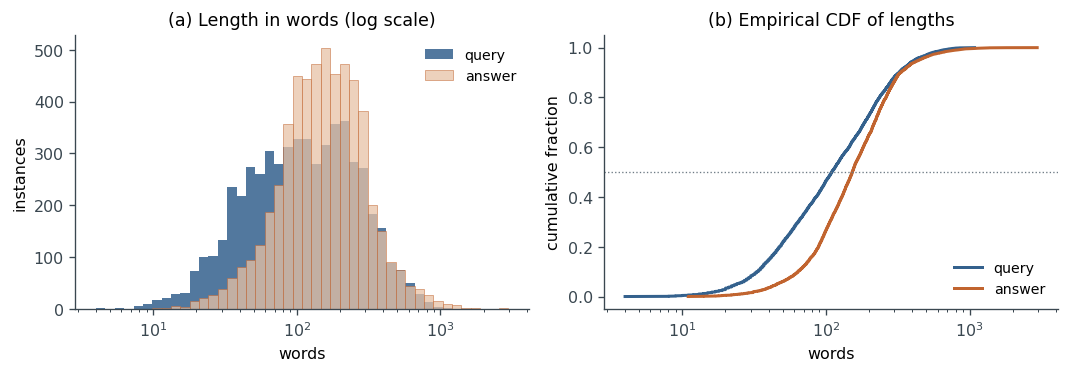

Saved: fig3_lengths.pdf / .png


In [3]:
def clean(s):
    return re.sub(r"\s+", " ", str(s).replace("_x000D_", " ")).strip()

len_q = df["consulta"].map(lambda t: len(clean(t).split()))
len_r = df["resolucion_consulta"].map(lambda t: len(clean(t).split()))
print(f"Query length   : median={len_q.median():.0f}  p90={len_q.quantile(.9):.0f}")
print(f"Response length: median={len_r.median():.0f}  p90={len_r.quantile(.9):.0f}  max={len_r.max():,}")

# ---- Fig. 3: text lengths ----
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
bins = np.logspace(np.log10(max(len_q.min(),1)), np.log10(len_r.max()), 45)
ax[0].hist(len_q, bins=bins, color=AZUL,      alpha=.85, label="query")
ax[0].hist(len_r, bins=bins, color=TERRA_SUAVE, alpha=.75, label="answer",
           edgecolor=TERRA, linewidth=.4)
ax[0].set_xscale("log")
ax[0].set_title("(a) Length in words (log scale)")
ax[0].set_xlabel("words"); ax[0].set_ylabel("instances"); ax[0].legend()
estilo(ax[0])

for serie, colr, lbl in [(len_q, AZUL, "query"), (len_r, TERRA, "answer")]:
    x = np.sort(serie); y = np.arange(1, len(x)+1)/len(x)
    ax[1].plot(x, y, color=colr, lw=1.8, label=lbl)
ax[1].set_xscale("log")
ax[1].axhline(0.5, color=GRIS, lw=.8, ls=":")
ax[1].set_title("(b) Empirical CDF of lengths")
ax[1].set_xlabel("words"); ax[1].set_ylabel("cumulative fraction"); ax[1].legend(loc="lower right")
estilo(ax[1], grid_axis="both")

plt.tight_layout()
plt.savefig("fig3_lengths.pdf", bbox_inches="tight")
plt.savefig("fig3_lengths_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()
print("Saved: fig3_lengths.pdf / .png")

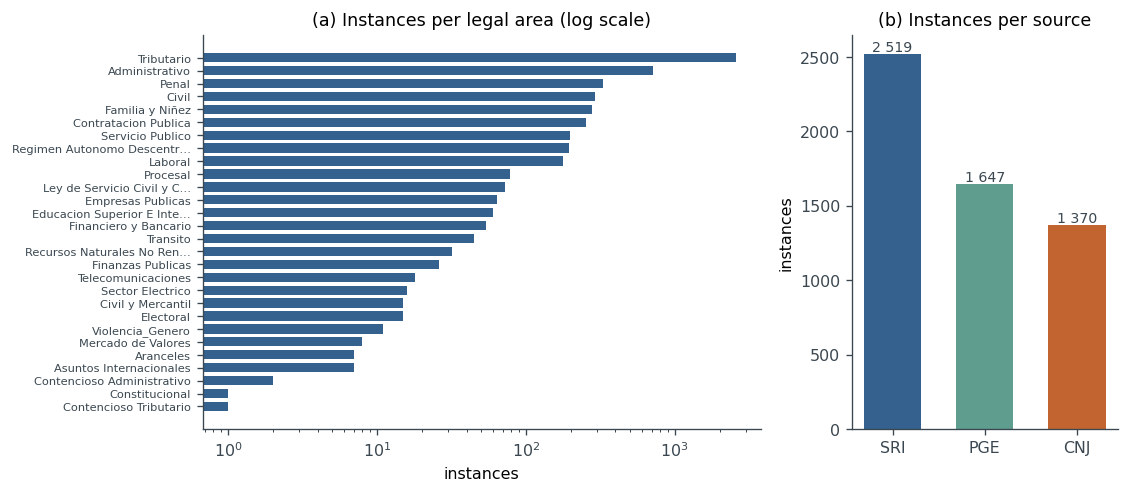

Top-5 legal areas: ['TRIBUTARIO', 'ADMINISTRATIVO', 'PENAL', 'CIVIL', 'FAMILIA, NIÑEZ, ADOLESCENCIA Y ADOLESCENTES INFRACTORES']
Top-5 share: 75.5%   Tributario: 46.4%
Saved: fig4_composition.pdf / .png


In [4]:
# Readable legal-area labels: title case and truncation
def abrev(m, n=26):
    t = str(m).title().replace(" Y ", " y ").replace(" De ", " de ").replace(" Del ", " del ")
    t = t.replace("Familia, Niñez, Adolescencia y Adolescentes Infractores", "Familia y Niñez")
    return t if len(t) <= n else t[:n-1].rstrip() + "…"
# ---- Fig. 4: composition by legal area and source ----
mat = df["materia"].value_counts()
fue = df["fuente"].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.2), gridspec_kw={"width_ratios": [2.1, 1]})

top = mat.sort_values()
ax[0].barh([abrev(m) for m in top.index], top.values, color=AZUL, height=.72)
ax[0].set_xscale("log")
ax[0].set_title("(a) Instances per legal area (log scale)")
ax[0].set_xlabel("instances")
ax[0].tick_params(axis="y", labelsize=6.8)
estilo(ax[0], grid_axis="x")

ax[1].bar(fue.index, fue.values, color=[COL_FUENTE.get(f, GRIS) for f in fue.index], width=.62)
for i, v in enumerate(fue.values):
    ax[1].text(i, v, f"{v:,}".replace(",", " "), ha="center", va="bottom", fontsize=8.5, color="#3A4750")
ax[1].set_title("(b) Instances per source")
ax[1].set_ylabel("instances")
estilo(ax[1])

plt.tight_layout();
plt.savefig("fig4_composition.pdf", bbox_inches="tight");
plt.savefig("fig4_composition_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()

top5 = mat.head(5)
print(f"Top-5 legal areas: {list(top5.index)}")
print(f"Top-5 share: {top5.sum()/len(df)*100:.1f}%   Tributario: {mat.iloc[0]/len(df)*100:.1f}%")
print("Saved: fig4_composition.pdf / .png")

### 3. Source and legal area (Fig. 5 and Cramér's V)

Builds the source-by-legal-area table, draws it as a heat map on a logarithmic color scale, and measures the association between the two variables with Cramér's V.


Cramér's V (source × legal area) = 0.93


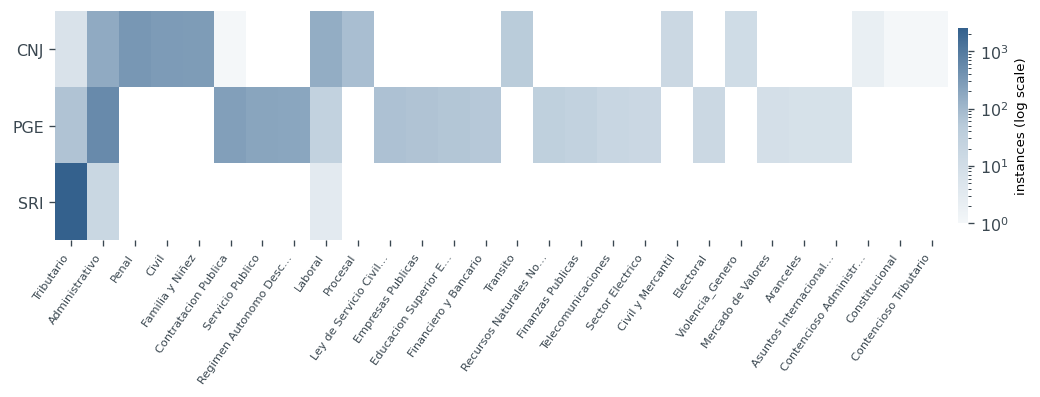

Saved: fig5_source_subject.pdf / .png


In [5]:
from matplotlib.colors import LogNorm
from scipy.stats import chi2_contingency

ct = pd.crosstab(df["fuente"], df["materia"])
# order the legal areas by total frequency
orden = ct.sum(0).sort_values(ascending=False).index
ct = ct[orden]

chi2, _, _, _ = chi2_contingency(ct)
n = ct.values.sum(); k = min(ct.shape) - 1
V = np.sqrt(chi2 / (n * k))
print(f"Cramér's V (source × legal area) = {V:.2f}")

fig, ax = plt.subplots(figsize=(9.5, 3.4))
cmap = mpl.colors.LinearSegmentedColormap.from_list("juris", ["#F4F7F9", AZUL_SUAVE, AZUL])
im = ax.imshow(ct.values, aspect="auto", cmap=cmap, norm=LogNorm(vmin=1, vmax=ct.values.max()))
ax.set_yticks(range(len(ct.index)), ct.index)
ax.set_xticks(range(len(ct.columns)), [abrev(m, 22) for m in ct.columns], rotation=55, ha="right", fontsize=6.8)
ax.grid(visible=False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=.85, pad=.01)
cb.set_label("instances (log scale)", fontsize=8)
cb.outline.set_visible(False)
#ax.set_title(f"Source × subject matter matrix  (Cramér's V = {V:.2f})")
plt.tight_layout(); plt.savefig("fig5_source_subject.pdf", bbox_inches="tight");
plt.savefig("fig5_source_subject_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()
print("Saved: fig5_source_subject.pdf / .png")

### 4. Word overlap and legal citations

- **Jaccard overlap** between the content words of each query and those of its response.
- **Lexical recall:** the fraction of a query's content words that also appear in its response.
- **Legal citations:** the number of articles cited in `base_legal` for each instance.


In [6]:
def norm(t):
    t = unicodedata.normalize("NFD", clean(t).lower())
    return re.findall(r"[a-z0-9]+", "".join(c for c in t if unicodedata.category(c) != "Mn"))

STOP = set("de la el en y a los del las un una que por con para es al se su o e lo como mas "
           "pero sus le ya fue este si porque esta entre cuando muy sin sobre tambien me hasta "
           "hay donde quien desde todo nos".split())

def toks(t):
    return [w for w in norm(t) if len(w) > 2 and w not in STOP]

def jaccard(a, b):
    A, B = set(a), set(b)
    return len(A & B) / len(A | B) if (A | B) else 0.0

qt = df["consulta"].map(toks)
rt = df["resolucion_consulta"].map(toks)

J  = np.array([jaccard(a, b) for a, b in zip(qt, rt)])
LR = np.array([len(set(a) & set(b)) / len(set(a)) if a else 0.0 for a, b in zip(qt, rt)])

def n_citas(t):
    return len(re.findall(r"\b[Aa]rt(?:[ií]culo|\.)?\s*\d+", str(t)))
CA = df["base_legal"].fillna("").map(n_citas)
has_bl = df["base_legal"].notna()

print(f"Jaccard overlap   : median={np.median(J):.3f}  mean={J.mean():.3f}  p90={np.quantile(J,.9):.3f}")
print(f"Lexical recall    : median={np.median(LR):.3f}  mean={LR.mean():.3f}")
print(f"Pairs with J<0.05 : {(J<0.05).mean()*100:.1f}%")
print(f"Legal citations   : median={CA[has_bl].median():.0f}  mean={CA[has_bl].mean():.1f}")
print(f"base_legal present: {has_bl.mean()*100:.1f}%")

Jaccard overlap   : median=0.141  mean=0.152  p90=0.258
Lexical recall    : median=0.327  mean=0.357
Pairs with J<0.05 : 8.6%
Legal citations   : median=6  mean=6.9
base_legal present: 98.8%


### 5. Similarity between queries (TF-IDF)

For each query, finds the most similar other query by TF-IDF cosine similarity. This is the distribution shown in panel (c) of Fig. 6.


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

X = TfidfVectorizer(max_features=50000, ngram_range=(1,2)).fit_transform(df["consulta"].astype(str))
N = X.shape[0]
nn = np.zeros(N)
B = 512
for s in range(0, N, B):
    e = min(s+B, N)
    sim = cosine_similarity(X[s:e], X)
    for i in range(e-s):
        sim[i, s+i] = 0
    nn[s:e] = sim.max(1)

print(f"Nearest query (TF-IDF cosine): median={np.median(nn):.3f}  max={nn.max():.3f}")
print(f"Queries with a nearest query at >=0.90: {(nn>=0.90).sum()}   >=0.80: {(nn>=0.80).sum()}")

Nearest query (TF-IDF cosine): median=0.290  max=0.963
Queries with a nearest query at >=0.90: 68   >=0.80: 234


### 6. Diagnostics figure (Fig. 6)

Draws the three panels: (a) Jaccard overlap, (b) cited legal provisions, and (c) nearest-query similarity.


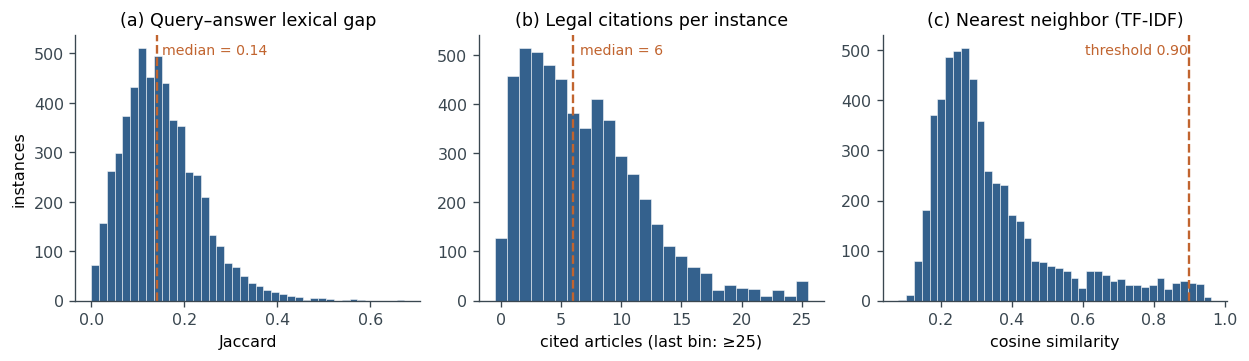

Saved: fig6_diagnostics.pdf / .png


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.1))

# (a) Jaccard overlap
ax[0].hist(J, bins=40, color=AZUL, edgecolor="white", linewidth=.3)
ax[0].axvline(np.median(J), color=TERRA, ls="--", lw=1.4)
ax[0].text(np.median(J)+.012, ax[0].get_ylim()[1]*.93 if ax[0].get_ylim()[1]>0 else 1,
           f"median = {np.median(J):.2f}", color=TERRA, fontsize=8.5)
ax[0].set_title("(a) Query–answer lexical gap")
ax[0].set_xlabel("Jaccard"); ax[0].set_ylabel("instances")

# (b) Legal citations: the last bar groups >=25 (stated on the axis)
ca = CA[has_bl].clip(0, 25)
ax[1].hist(ca, bins=np.arange(0, 27)-.5, color=AZUL, edgecolor="white", linewidth=.3)
ax[1].axvline(CA[has_bl].median(), color=TERRA, ls="--", lw=1.4)
ax[1].set_title("(b) Legal citations per instance")
ax[1].set_xlabel("cited articles (last bin: ≥25)")
ax[1].text(CA[has_bl].median()+.6, ax[1].get_ylim()[1]*.93,
           f"median = {CA[has_bl].median():.0f}", color=TERRA, fontsize=8.5)

# (c) Nearest query
ax[2].hist(nn, bins=40, color=AZUL, edgecolor="white", linewidth=.3)
ax[2].axvline(0.90, color=TERRA, ls="--", lw=1.4)
ax[2].text(0.895, ax[2].get_ylim()[1]*.93, "threshold 0.90", color=TERRA,
           fontsize=8.5, ha="right")
ax[2].set_title("(c) Nearest neighbor (TF-IDF)")
ax[2].set_xlabel("cosine similarity")

for a in ax: estilo(a)
plt.tight_layout(); plt.savefig("fig6_diagnostics.pdf", bbox_inches="tight");
plt.savefig("fig6_diagnostics_600dpi.png", dpi=600, bbox_inches="tight")

plt.show()
print("Saved: fig6_diagnostics.pdf / .png")

## Part B — Semantic structure (needs a GPU)

The following cells download BGE-M3 and compute embeddings. Enable a GPU first: Runtime → Change runtime type → GPU.


In [9]:
!pip -q install sentence-transformers umap-learn
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device:", torch.cuda.get_device_name(0))

GPU available: True
Device: NVIDIA L4


### 7. BGE-M3 embeddings

Encodes all queries and all responses with BGE-M3 and normalizes the embeddings.


In [10]:
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("BAAI/bge-m3", device="cuda" if torch.cuda.is_available() else "cpu")

emb_q = model.encode(df["consulta"].tolist(),  batch_size=32, show_progress_bar=True, normalize_embeddings=True)
emb_r = model.encode(df["resolucion_consulta"].tolist(), batch_size=16, show_progress_bar=True, normalize_embeddings=True)
print("Query embeddings shape:", emb_q.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.27GB            

... (10 outputs left out)

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Batches:   0%|          | 0/173 [00:00<?, ?it/s]

Batches:   0%|          | 0/346 [00:00<?, ?it/s]

Query embeddings shape: (5536, 1024)


### 8. Lexical versus semantic similarity (Fig. 7)

Computes the cosine similarity between each query and its response, and its Spearman correlation with the Jaccard overlap. As a reference, it also computes the mean similarity of random query–response pairs. The figure highlights the pairs with almost no shared words (J < 0.05) whose similarity is above the median.


Spearman(Jaccard, BGE-M3 cosine) = 0.669
Query-response cosine: median=0.737
Random-pair cosine   : mean=0.417  (reference level)
Pairs with J<0.05 and cosine>=median: 0.3%


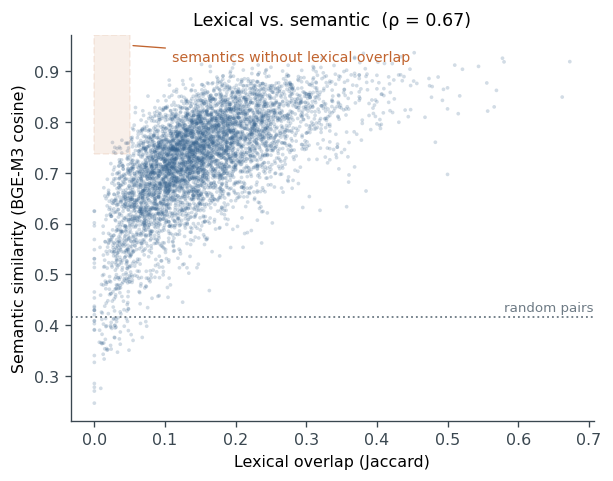

Saved: fig7_lexical_vs_semantic.pdf / .png


In [11]:
from scipy.stats import spearmanr

cos_qr = (emb_q * emb_r).sum(1)
rho, p = spearmanr(J, cos_qr)

# Scale reference: mean cosine of random query-answer pairs (anisotropy)
rng = np.random.default_rng(0)
perm = rng.permutation(len(df))
cos_rand = (emb_q * emb_r[perm]).sum(1)
print(f"Spearman(Jaccard, BGE-M3 cosine) = {rho:.3f}")
print(f"Query-response cosine: median={np.median(cos_qr):.3f}")
print(f"Random-pair cosine   : mean={cos_rand.mean():.3f}  (reference level)")

# Region with semantic similarity but almost no shared words
J_TH, C_TH = 0.05, np.median(cos_qr)
frac = ((J < J_TH) & (cos_qr >= C_TH)).mean()
print(f"Pairs with J<{J_TH} and cosine>=median: {frac*100:.1f}%")

fig, ax = plt.subplots(figsize=(5.2, 4.1))
ax.scatter(J, cos_qr, s=5, alpha=.22, color=AZUL, edgecolors="none", rasterized=True)

# highlight the low-Jaccard / high-cosine region
ylim = ax.get_ylim()
ax.add_patch(plt.Rectangle((0, C_TH), J_TH, ylim[1]-C_TH, facecolor=TERRA, alpha=.10,
                           edgecolor=TERRA, linewidth=1.0, ls="--"))
ax.annotate("semantics without lexical overlap", xy=(J_TH, ylim[1]-.02),
            xytext=(J_TH+.06, ylim[1]-.03),
            color=TERRA, fontsize=8.5, va="top",
            arrowprops=dict(arrowstyle="-", color=TERRA, lw=.8))
ax.axhline(cos_rand.mean(), color=GRIS, ls=":", lw=1.1)
ax.text(ax.get_xlim()[1], cos_rand.mean()+.006, "random pairs", color=GRIS,
        fontsize=8, ha="right", va="bottom")
ax.set_ylim(ylim)
ax.set_xlabel("Lexical overlap (Jaccard)")
ax.set_ylabel("Semantic similarity (BGE-M3 cosine)")
ax.set_title(f"Lexical vs. semantic  (ρ = {rho:.2f})")
estilo(ax, grid_axis="both")
plt.tight_layout()
plt.savefig("fig7_lexical_vs_semantic.pdf", bbox_inches="tight")
plt.savefig("fig7_lexical_vs_semantic_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()
print("Saved: fig7_lexical_vs_semantic.pdf / .png")

### 9. Separability in the embedding space

Computes the Fisher ratio and the silhouette score of the query embeddings, grouped by legal area (areas with at least 30 instances) and by source. Both are computed in the original 1,024 dimensions, not in the two-dimensional projection.


In [12]:
from sklearn.metrics import silhouette_score

def fisher_ratio(X, y):
    mu = X.mean(0)
    Sw = Sb = 0.0
    for c in np.unique(y):
        Xc = X[y==c]; muc = Xc.mean(0)
        Sw += ((Xc-muc)**2).sum()
        Sb += len(Xc) * ((muc-mu)**2).sum()
    return Sb/Sw

# By legal area (areas with N>=30) and by source
mat_counts = df["materia"].value_counts()
mats_ok = mat_counts[mat_counts >= 30].index
mask = df["materia"].isin(mats_ok).values

fr_materia = fisher_ratio(emb_q[mask], df.loc[mask, "materia"].values)
fr_fuente  = fisher_ratio(emb_q, df["fuente"].values)
sil_mat = silhouette_score(emb_q[mask], df.loc[mask, "materia"].values,
                           metric="cosine", sample_size=3000, random_state=0)
sil_fue = silhouette_score(emb_q, df["fuente"].values,
                           metric="cosine", sample_size=3000, random_state=0)

print(f"Fisher ratio [1024-d, legal area N>=30] = {fr_materia:.2f}")
print(f"Fisher ratio [1024-d, source]           = {fr_fuente:.2f}")
print(f"Silhouette (cosine): legal area = {sil_mat:.3f}   source = {sil_fue:.3f}")

Fisher ratio [1024-d, legal area N>=30] = 0.10
Fisher ratio [1024-d, source]           = 0.08
Silhouette (cosine): legal area = 0.024   source = 0.091


### 10. UMAP projection (Fig. 8)

Projects the query embeddings to two dimensions with UMAP and reports its trustworthiness@20, which measures how well local neighborhoods are preserved. The figure shows the twelve largest legal areas, with one color family per source: blues for SRI, greens for PGE, and oranges for CNJ.


In [13]:
import umap
from sklearn.manifold import trustworthiness

reducer = umap.UMAP(n_neighbors=30, min_dist=0.1, metric="cosine", random_state=42)
xy_umap = reducer.fit_transform(emb_q)

tw = trustworthiness(emb_q, xy_umap, n_neighbors=20, metric="cosine")
print(f"Trustworthiness@20 (UMAP) = {tw:.3f}")

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Trustworthiness@20 (UMAP) = 0.891


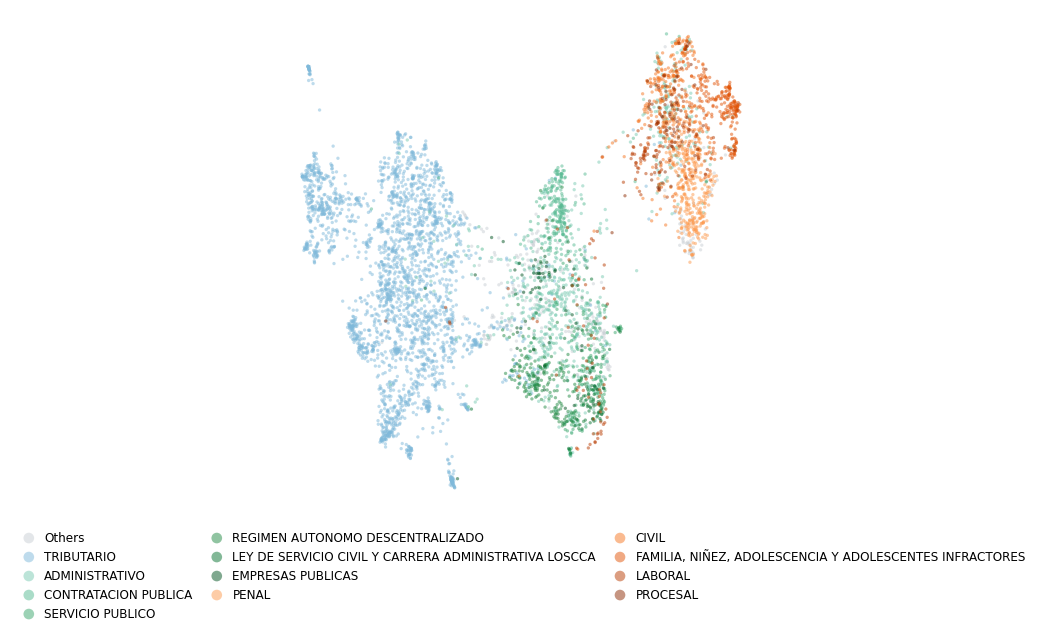

Saved: fig8_umap_subject_matter.pdf / .png


In [14]:
# ---- Fig. 8: UMAP colored by the 12 largest legal areas, with color families by source ----
top12 = df["materia"].value_counts().head(12).index.tolist()
mat_lbl = df["materia"].where(df["materia"].isin(top12), "Others")

# dominant source of each legal area (it sets the color family)
fuente_dom = df.groupby("materia")["fuente"].agg(lambda s: s.value_counts().idxmax())

familias = {"SRI": mpl.colormaps["Blues"], "PGE": mpl.colormaps["BuGn"], "CNJ": mpl.colormaps["Oranges"]}
col_materia = {}
por_fuente = {f: [m for m in top12 if fuente_dom.get(m) == f] for f in ["SRI", "PGE", "CNJ"]}
for f, mats in por_fuente.items():
    cmap = familias[f]
    for i, m in enumerate(mats):
        col_materia[m] = cmap(0.45 + 0.5 * (i / max(len(mats)-1, 1)))
col_materia["Others"] = "#C9CFD4"

fig, ax = plt.subplots(figsize=(7.2, 5.4))
orden_plot = ["Others"] + [m for f in ["SRI","PGE","CNJ"] for m in por_fuente[f]]
for m in orden_plot:
    msk = (mat_lbl == m).values
    ax.scatter(xy_umap[msk,0], xy_umap[msk,1], s=4, alpha=.5,
               color=col_materia[m], label=m, edgecolors="none", rasterized=True)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(visible=False)
for s in ax.spines.values(): s.set_visible(False)
leg = ax.legend(markerscale=3.2, ncol=3, fontsize=7.2, loc="upper center",
                bbox_to_anchor=(0.5, -0.02), columnspacing=1.0, handletextpad=.3)
plt.tight_layout()
plt.savefig("fig8_umap_subject_matter.pdf", bbox_inches="tight")
plt.savefig("fig8_umap_subject_matter_600dpi.png", dpi=600, bbox_inches="tight")
plt.show()
print("Saved: fig8_umap_subject_matter.pdf / .png")